# Intro to MLE: Normality


In [ ]:
import numpy as np 
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from sklearn.model_selection import train_test_split

df = pd.read_csv('./data/ames_prices.csv')

## Estimating Models
- Where do models "come from"? How do we set up scenarios with fidelity to reality, and extract meaningful models and predictions?
- The main framework for doing this is called **Maximum Likelihood Estimation**
- We:
    1. Model the **error term** explicitly with a parametric distribution, linking the model to data by way of the **parameters**
    2. Compute the joint density of observing the data (the likelihood)
    3. Maximize that density (the maximum likelihood estimator)
- Most models you know (OLS, Logistic Regression, Poisson Regression, etc.) are a version of this general concept

# 1. Multivariate Densities

## Joint Distribution and Density
- The distribution function for $(X_1, ..., X_N)$ is given by
$$
F_{X_1, X_2, ... , X_N}(x_1, x_2, ..., x_N) = \mathbb{P}\left( \{ z \in \mathcal{Z} : X_1 \le x_1, X_2 \le x_2, ..., X_N \le x_n \} \right),
$$
and the density function is given by
$$
f_{X_1, X_2, ... , X_N}(x_1, x_2, ..., x_N) = \dfrac{\partial ^N F_{X_1, X_2, ... , X_N}(x_1, x_2, ..., x_N)}{\partial x_1 \partial x_2 ... \partial x_N},
$$
- These aren't very expressive or intuitive. What we want to know is, how do these variables "move together"?

## Independence
- Before we dive into non-trivial examples of random vectors, we have a nice edge case: If it's true that
$$
f_{X_1, X_2, ..., X_n}(x_1, x_2, ..., x_n) = f_{X_1}(x_1) \times f_{X_2}(x_2) \times ... \times f_{X_n}(x_n)
$$
then we say that $(X_1,...,X_n)$ are **independent random variables**
- We are basically saying that the realizations of each random variable $X_i$ are unrelated to the realizations of the others
- For example, flip a coin and then flip it again: Independence
- We typically write this as
$$
f_{X_1, X_2, ..., X_n}(x_1, x_2, ..., x_n) = \prod_{i=1}^n f_{X_i}(x_i)
$$



## Exercise: Covariance and Independence
- The **covariance** of $X$ and $Y$ is
$$
\text{cov}(X,Y) = \int_{x,y} (x-\mathbb{E}[X])(y-\mathbb{E}[Y])f_{XY}(x,y) dxdy = \mathbb{E}_{XY}[ (x-\mu_X)(y-\mu_Y)]
$$
- Show that if $f_{XY}(x,y)=f_X(x)f_Y(y)$, then $\text{cov}(X,Y)=0$
- Provide an example where $\text{cov}(X,Y)\approx 0$ but $f_{XY}(x,y)\neq 0$
- The covariance doesn't characterize joint random variables except in a few special cases

## Bivariate Normal
- Let's start with something concrete: A pair of variables $(X,Y)$ over the same probability space, having a **bivariate normal distribution**
- It would not be very interesting to have $f_{XY}(x,y) = f_X(x)f_Y(y)$: That's just two normals living in the same space, with no connection. We want $X$ and $Y$ to carry information about one another. This complexity comes at a cost
- The bivariate normal density function is:
$$
f_{XY}(x,y) = \dfrac{1}{2 \pi \sqrt{1-\rho^2} \sigma_x \sigma_y} \exp \left\lbrace - \frac{1}{2(1-\rho^2)} \left[ \left( \frac{x-\mu_X}{\sigma_X}\right)^2 + \left( \frac{y-\mu_Y}{\sigma_Y}\right)^2 - 2 \rho \frac{(x-\mu_X)(y-\mu_Y)}{\sigma_X \sigma_Y} \right] \right\rbrace
$$
where $\sigma_X, \sigma_Y > 0$ and $-1 < \rho <1 $

## Bivariate Normal
- Slightly less hideous: Letting $z = [x,y]^{\top}$ and $\mu = [\mu_X, \mu_Y]^{\top}$,
$$
f_{z}(z) = \dfrac{1}{\sqrt{(2\pi)^2 \det(\Sigma)}} \exp \left\lbrace - \frac{(z-\mu)^{\top} \Sigma^{-1}(z-\mu)}{2}\right\rbrace
$$
where
$$
\Sigma = \left[ \begin{array}{cc} \sigma_X^2 & \rho \sigma_X \sigma_Y \\ \rho \sigma_X \sigma_Y & \sigma_Y^2 \end{array}\right]
$$
- If you squint, it's as if you're substituting $(x-\mu)/\sigma$ in the one-dimensional version for $ (z-\mu)^{\top} \Sigma^{-1}(z-\mu)$, and $1/\sigma$ for $1/\det(\Sigma)$


In [53]:
## Generate MVN data:
rho = -0.6
sigma_x = 1
sigma_y = 1
mu = [0, 0]

Sigma = [[sigma_x**2, rho*sigma_x*sigma_y], 
         [rho*sigma_x*sigma_y, sigma_y**2]] 

x, y = np.random.multivariate_normal(mu, Sigma, 10000).T
df = pd.DataFrame({'x': x, 'y': y})

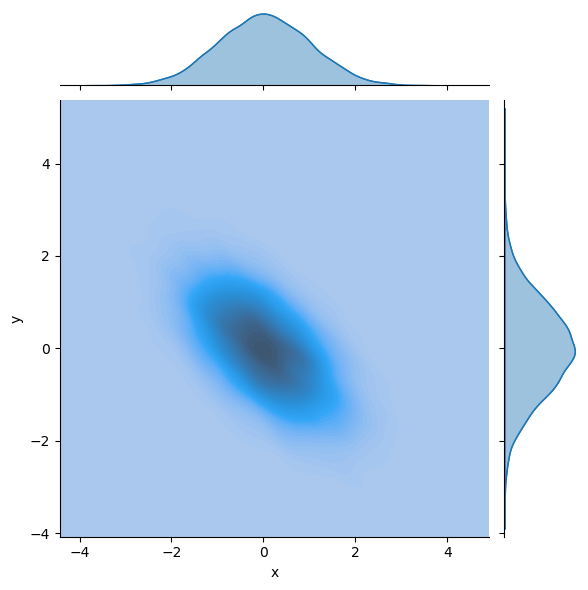

In [54]:
g = sns.jointplot(
    data=df, x='x', y='y', kind='kde',  
    fill=True,thresh=0,levels=50)
g.plot_marginals(sns.kdeplot, fill=True)
plt.show()

<Axes: xlabel='x', ylabel='y'>

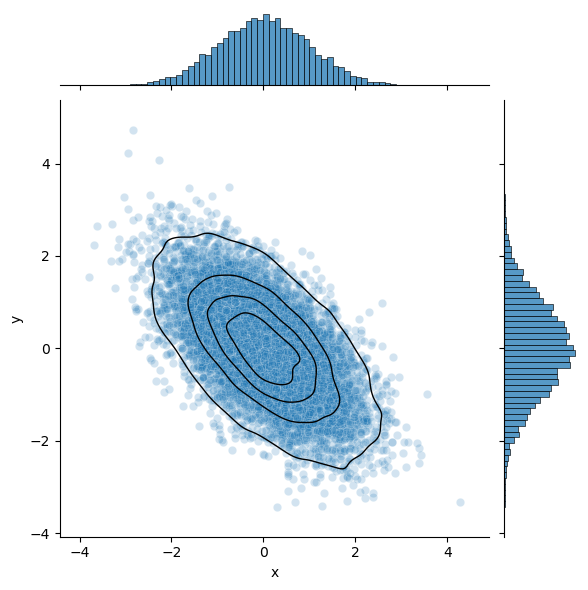

In [55]:
sns.jointplot(data=df, x='x', y='y', kind='scatter',alpha=.2)
sns.kdeplot(data=df, x='x', y='y', levels=5, color='k', linewidths=1)

## Multivariate Normal
- This equation generalizes to the general pdf for a multivariate normal in $n$ dimensions:
$$
f_X(x_1, ..., x_N) = \dfrac{1}{\sqrt{(2\pi)^n \det(\Sigma)}} \exp \left\lbrace - \frac{(z-\mu)^{\top} \Sigma^{-1}(z-\mu)}{2}\right\rbrace
$$
where 
$$
\Sigma = \left[ \begin{array}{cccc} \sigma_1^2 & \text{cov}(X_1,X_2) & ... & \text{cov}(X_1,X_N) \\  \text{cov}(X_2,X_1) & \sigma_2^2 & ... & \text{cov}(X_2,X_N) \\ \vdots & \vdots & \ddots & \vdots \\ \text{cov}(X_N,X_1) & \text{cov}(X_N,X_2) & ... & \sigma_N^2 \end{array}\right]
$$
- This quantity, $\sqrt{(z-\mu)^{\top} \Sigma^{-1}(z-\mu)}$ is called the **Mahalanobis distance** from $z$ to $\mu$: It's a variance-weighted distance metric
- This *is* a case where means and variances/covariances totally describe the multi-dimensional behavior of the random variable

## Exercise
- Suppose $X$ and $Y$ are distributed bivariate normal. Show that if $\rho=0$, then $X$ and $Y$ are independent.
- Show that if $\Sigma$ is a diagonal matrix, then $X_1, X_2, ..., X_n$ are independent.
- Show that if $\Sigma$ is a diagonal matrix and all the $\sigma_i^2$ and all the $\mu_i$ are equal, then $X_1, X_2, ..., X_n$ are independently distributed random variables with the same distribution, $N(\mu, \sigma^2)$

# 2. The Normal Likelihood

## The Normal Density
- Suppose each observation $y_i$ is normally distributed, with mean $\mu$ and standard deviation $\sigma$, so the density is
$$
f[y_i|\mu, \sigma] = \dfrac{1}{\sqrt{2\pi} \sigma} \exp \left\lbrace -\frac{1}{2} \left( \frac{y_i - \mu}{\sigma}\right)^2\right\rbrace
$$
- It doesn't have to be Normal, but let's start here

## The Likelihood
- **The Likelihood is the product of densities/probabilities of the observed data**:
$$
\mathcal{L}[y|\mu, \sigma] = \prod_{i=1}^n f[y_i|\mu, \sigma] = \prod_{i=1}^n \dfrac{1}{\sqrt{2\pi} \sigma} \exp \left\lbrace -\frac{1}{2} \left( \frac{y_i - \mu}{\sigma}\right)^2\right\rbrace
$$
- For a variety of reasons, we now want to compute the **log-likelihood**:
$$
\begin{alignat*}{2}
L[y|\mu,\sigma] &=& \sum_{i=1}^n \left[ - \log\left( \sqrt{2\pi} \sigma\right) - \log \left( \exp \left( \frac{1}{2} \left( \frac{y_i - \mu}{\sigma}\right)^2 \right) \right)  \right] \\
&=& \sum_{i=1}^n \left[ - \log\left( \sqrt{2\pi} \right) - \log\left( \sigma\right) -\frac{1}{2} \left( \frac{y_i - \mu}{\sigma}\right)^2 \right] \\
&=&  - n\log\left( \sqrt{2\pi} \right) - n\log\left( \sigma\right) - \frac{1}{2\sigma^2} \sum_{i=1}^n \left( y_i - \mu \right)^2\\
\end{alignat*}
$$

## The Log-Likelihood
- Notice the SSE appears:
$$
L[y|\mu,\sigma] = - n\log\left( \sqrt{2\pi} \right) - n\log\left( \sigma\right) - \frac{1}{2\sigma^2} \underbrace{\sum_{i=1}^n \left( y_i - \mu \right)^2}_{\text{Sum of Squared Error}} 
$$
- You cannot "not make assumptions" when estimating/predicting: If you are minimizing SSE/MSE/RMSE, you are assuming a normal density for the errors 

## Maximizing the Likelihood: $\mu$
$$
\begin{alignat*}{2}
\frac{\partial L[y|\hat{\mu},\hat{\sigma}]}{\partial \mu} &=&  \frac{1}{\sigma^2} \sum_{i=1}^n \left( y_i - \hat{\mu} \right)  \\
0 &=& \sum_{i=1}^n  y_i - n \hat{\mu} \\
\hat{\mu} &=& \frac{1}{n} \sum_{i=1}^n y_i
\end{alignat*}
$$
The sample mean!

## Maximizing the Likelihood: $\sigma$
$$
\begin{alignat*}{2}
\frac{\partial L[y| \hat{\mu},\hat{\sigma}]}{\partial \sigma} &=&  \frac{1}{\hat{\sigma}^3}\sum_{i=1}^n \left( y_i - \hat{\mu} \right)^2- \frac{n}{ \hat{\sigma} }  \\
0 &=& \sum_{i=1}^n \left( y_i - \hat{\mu} \right)^2- n \hat{\sigma}^2 \\
\hat{\sigma}^2  &=& \frac{1}{n} \sum_{i=1}^n \left( y_i - \hat{\mu} \right)^2
\end{alignat*}
$$
The sample variance!

## Example: House Price

[Text(0.5, 1.0, 'Log of Price Distribution'),
 Text(0.5, 0, 'Log of Price'),
 Text(0, 0.5, 'Density')]

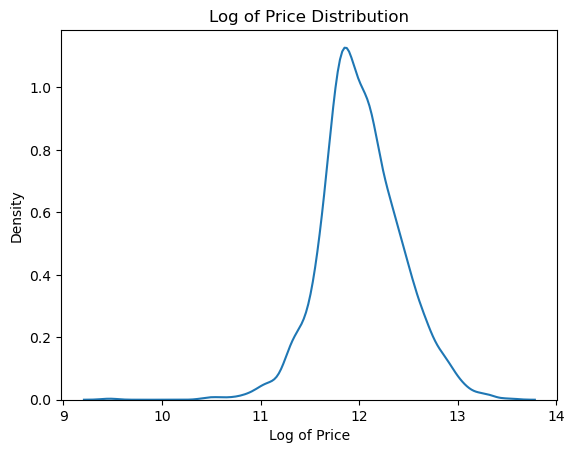

In [36]:
y = np.log( df['price'] )
sns.kdeplot(y).set(title='Log of Price Distribution', xlabel='Log of Price', ylabel='Density')

MLE Estimates: mu_hat = 12.0210, sigma_hat = 0.4076


Text(0.5, 1.0, 'Log of Price Distribution and Normal Density')

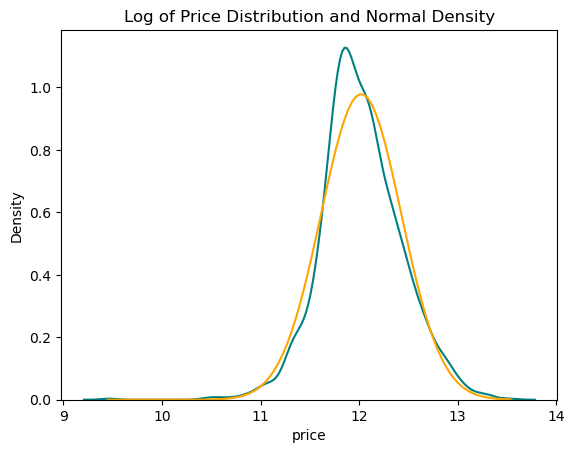

In [37]:
# MLE Estimation

def normal_density(x, mu, sigma):
    return (1/(sigma * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((x - mu)/sigma)**2)

mu_hat = y.mean()
sigma_hat = y.std()
print(f'MLE Estimates: mu_hat = {mu_hat:.4f}, sigma_hat = {sigma_hat:.4f}')
density_hat = normal_density( np.linspace(y.min(), y.max(),100), mu_hat, sigma_hat)

sns.kdeplot(y, label='Log of Price Distribution', color='teal')
plt.plot(np.linspace(y.min(), y.max(),100), density_hat, label='Normal Density', color='orange')
plt.title('Log of Price Distribution and Normal Density')


## Confidence Interval
- Since the MLE $\hat{\mu}$ is just the sample mean, we can estimate its standard error with $\hat{\sigma}/\sqrt{n}$
- Then a 95% CI for $\mu$ is
$$
\left( \hat{\mu} - 1.96 \times \frac{\hat{\sigma}}{\sqrt{n}}, \quad \hat{\mu} + 1.96 \times \frac{\hat{\sigma}}{\sqrt{n}}\right)
$$
- For other models, this question will be more complex

In [38]:
L = mu_hat - 1.96 * sigma_hat / np.sqrt(len(y))
U = mu_hat + 1.96 * sigma_hat / np.sqrt(len(y))
print(f'95% Confidence Interval for mu: ({L:.4f}, {U:.4f})')

95% Confidence Interval for mu: (12.0062, 12.0357)


## Warning: Going Back to the Original Scale
- We very often take logs and very often fail to handle the return to the original scale correctly
- This is much harder than it seems, because if our logged values are $Y = \log(X)$, then the original values are $X = e^Y$, and $\mathbb{E}[e^Y]$ and standard errors need to be computed:
$$
\hat{\theta} = \exp \left\lbrace \hat{\mu} + \frac{\hat{\sigma}^2}{2} \right\rbrace, \quad \widehat{SE}(\hat{\theta}) = \frac{\sigma^2}{n}+\frac{\sigma^4}{2n} 
$$
and the confidence interval is $e^{\hat{\theta} \pm 1.96 \times \widehat{SE}(\hat{\theta})}$,
$$
\left( \exp \left\lbrace \hat{\mu} + \frac{\hat{\sigma}^2}{2} - 1.96 \sqrt{\frac{\hat{\sigma}^2}{n}+\frac{\hat{\sigma}^4}{2n}} \right\rbrace, \quad \exp \left\lbrace \hat{\mu} + \frac{\hat{\sigma}^2}{2} + 1.96 \sqrt{\frac{\hat{\sigma}^2}{n}+\frac{\hat{\sigma}^4}{2n}} \right\rbrace \right)
$$

In [50]:
# MLE for mean house price in levels
mean_X = np.exp(mu_hat + 0.5 * sigma_hat**2)

# Delta-method standard error of the estimated mean
se_log_mean = np.sqrt(
    sigma_hat**2 / len(y) + sigma_hat**4 / (2 * len(y))
)

# 95% confidence interval
L_level = np.exp(mu_hat + 0.5 * sigma_hat**2 - 1.96 * se_log_mean)
U_level = np.exp(mu_hat + 0.5 * sigma_hat**2 + 1.96 * se_log_mean)

print(f'95% CI for mean house price: ({L_level:.4f}, {U_level:.4f})')
print(f'Mean house price: {df["price"].mean():.4f}')
print(f'Incorrect, naively exponentiated version: ({np.exp(L):.4f}, {np.exp(U):.4f})')

95% CI for mean house price: (177845.9502, 183393.8798)
Mean house price: 180796.0601
Incorrect, naively exponentiated version: (163768.6730, 168674.6852)


In [51]:
## Just bootstrap it

R = 5000
results = []
for r in range(R):
    y_r = np.random.choice(y, size=len(y), replace=True)
    mu_r = y_r.mean()
    sigma_r = y_r.std()
    mean_X_r = np.exp( mu_r + 0.5 * sigma_r**2 ) # Corrected mean house price in levels
    results.append(mean_X_r)
print(f'Bootstrap CI for mean house price: ({np.percentile(results, 2.5):.4f}, {np.percentile(results, 97.5):.4f})')

Bootstrap CI for mean house price: (177784.9227, 183450.5685)


## Prediction Interval
- With our fitted model, we can predict the density of $y$:
$$
f_Y(y) = \dfrac{1}{\sqrt{2\pi} \hat{\sigma}} \exp \left\lbrace -\frac{1}{2} \left( \frac{y - \hat{\mu} }{\hat{\sigma}}\right)^2\right\rbrace
$$
- With a fitted model, we can make predictions based on the density. This is called a **90% prediction interval** (and similarly for 95%/1.996 and 99%/2.575):
$$
\left( \hat{\mu} - 1.645 \times \hat{\sigma}, \quad \hat{\mu} + 1.645 \times \hat{\sigma} \right) 
$$
- Notice that $\hat{\sigma}$ is the standard deviation of the sample, not the standard error of the sampling distribution (we didn't bootstrap it, we just computed it)
- Why is this **not** a confidence interval? (for example, does the standard error go to zero as $n$ gets large? What's the standard error of the mean versus the standard deviation of the sample?)

## PIs on the Original Scale
- If $Y = \log(X)$ and we want to go back to the original data in $X$, then we need to adjusted the fitted density:
$$
\hat{f}_X(x) = \dfrac{1}{\sqrt{2\pi}\hat{\sigma}x} \exp \left\lbrace - \dfrac{(\log(x)-\hat{\mu})^2}{2\hat{\sigma}^2}\right\rbrace, \quad x > 0
$$
- However, our PI is actually just
$$
\left( e^{\hat{\mu - 1.645 \times \hat{\sigma}}}, \quad e^{\hat{\mu + 1.645 \times \hat{\sigma}}}\right)
$$
since we're treating $\hat{\mu}$ and $\hat{\sigma}$ as known, fixed estimates of model parameters (prediction) rather than random variables of the sample data subject to sampling variation (inference)
- Prediction is often much easier than inference

# 3. Parameterization

## The Parameters
- What is $\mu$? The mean of the distribution. What is $\sigma$? The standard deviation.
- If we replace $\mu$ with $x_i \beta$, we are modeling the mean by a linear function of $x$. Our model becomes
$$
y_i = x_i \beta + \sigma \varepsilon
$$
where $\varepsilon$ is standard normal
- Notice that
$$
\begin{alignat*}{2}
\mathbb{E}[y_i | x_i ] &=& \mathbb{E}[ x_i \beta + \sigma \varepsilon|x_i] = x_i \beta \\
\mathbb{V}[y_i | x_i ] &=& \mathbb{E}[ (x_i \cdot \beta + \sigma \varepsilon - \mathbb{E}[y_i | x_i ])^2|x_i] = \sigma^2
\end{alignat*}
$$
- The function $x_i \beta$ is the **conditional expectation function**: We are modeling $\mathbb{E}[y|x]$ by **assuming** it has the functional form $x \cdot \beta$
- You can set $\mu = g(x,\beta)$ and use whatever model you want; linear regression is just easy to interpret

## The Parameterized Model
$$
L(\beta,\sigma) = - n\log\left( \sqrt{2\pi} \right) - n\log\left( \sigma\right) - \frac{1}{2\sigma^2} \underbrace{\sum_{i=1}^n \left( y_i - x_i \beta \right)^2}_{\text{Sum of Squared Error}} 
$$
- Do you recognize this model? Minimize the SSE over $\beta$, with a linear predictor $\hat{y} = x_i \beta$?

## The Gradient

We know the solution for this model ($\hat{\beta}=(X^{\top}X)^{-1} (X^{\top}y)$), but in general, we can solve MLE models with gradient ascent (since we're maximizing)

The gradient with respect to $\beta$ is
$$
\nabla_\beta L(\beta,\sigma) = \frac{1}{\sigma^2} X^{\top}(y-X \beta)
$$
and with respect to $\sigma^2$ is
$$
\frac{\partial L(\beta, \sigma)}{\partial \sigma} =  \frac{-n}{\sigma} + \frac{(y-X\cdot \beta)\cdot (y-X\cdot \beta)}{\sigma^3}
$$
- You can solve numerically by gradient ascent with
$$
\left[ \begin{array}{c}
\beta_{t+1}\\
\sigma_{t+1}
\end{array}
\right] = \left[ \begin{array}{c}
\beta_{t}\\
\sigma_{t}
\end{array}
\right] + r \left[ \begin{array}{c}
\frac{1}{\sigma^2_t}  X^{\top}(y-X \beta_t)\\
  \frac{-n}{\sigma_t} - \frac{(y-X\cdot \beta_t)\cdot (y-X\cdot \beta_t)}{\sigma_t^3}
\end{array}
\right]
$$

## Bootstrap Inference

1. Take a 100% sample of the data with replacement
2. Refit the model on the bag and compute your statistic $\hat{S}_r$; compute predictions and MSE on the out-of-bag observations for model validation
3. Repeat steps 1 and 2 for $R$ replications to model taking draws from the sampling distribution of $S$, $[\hat{S}_1, ... , \hat{S}_R]$
4. Compute the standard deviation of $[\hat{S}_1, ... , \hat{S}_R]$ to estimate the standard error of $S$
5. Compute CIs 



## Asymptotic Confidence Intervals
- For linear regression, we do know the asymptotic formula for the standard errors of the regression coefficients, $\beta_k$:
$$
\text{SE}(\hat{\beta}_k) = \frac{\hat{\sigma}}{\sqrt{n}} \sqrt{ \left( \frac{X^{\top}X}{n}\right)^{-1}_{kk}}
$$
where 
$$
\hat{\sigma} = \sqrt{\frac{(y-X \cdot \hat{\beta})\cdot (y-X \cdot \hat{\beta})}{n}}
$$
- So a 95% asymptotic CI for $\hat{\beta}_k$ is
$$
\left( \hat{\beta}_k - 1.96 \times \frac{\hat{\sigma}}{\sqrt{n}} \sqrt{ \left( \frac{X^{\top}X}{n}\right)^{-1}_{kk}}, \quad \hat{\beta}_k + 1.96 \times \frac{\hat{\sigma}}{\sqrt{n}} \sqrt{ \left( \frac{X^{\top}X}{n}\right)^{-1}_{kk}}  \right) 
$$
- StatsModels reports an extremely slight variation on this

In [ ]:
import statsmodels.formula.api as smf

train, test = train_test_split(df, test_size=0.2, random_state=42)
# C() creates category indicators, with the lowest level as the reference.
# The log-area coefficient is the price elasticity, holding these categories fixed.
model = smf.ols(
    'np.log(price) ~ np.log(area) + C(Q("Overall.Qual")) + C(Q("Full.Bath"))',
    data=train,
).fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:          np.log(price)   R-squared:                       0.767
Model:                            OLS   Adj. R-squared:                  0.765
Method:                 Least Squares   F-statistic:                     546.1
Date:                Tue, 10 Nov 2026   Prob (F-statistic):               0.00
Time:                        01:33:52   Log-Likelihood:                 519.94
No. Observations:                2344   AIC:                            -1010.
Df Residuals:                    2329   BIC:                            -923.5
Df Model:                          14                                         
Covariance Type:            nonrobust                                         
==============================================================================================
                                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------
Intercept                      8.1191      0.161     50.465      0.000       7.804       8.435
C(Q("Overall.Qual"))[T.2]      0.2218      0.115      1.921      0.055      -0.005       0.448
C(Q("Overall.Qual"))[T.3]      0.6320      0.105      6.032      0.000       0.427       0.837
C(Q("Overall.Qual"))[T.4]      0.8305      0.100      8.334      0.000       0.635       1.026
C(Q("Overall.Qual"))[T.5]      1.0497      0.099     10.604      0.000       0.856       1.244
C(Q("Overall.Qual"))[T.6]      1.1540      0.099     11.633      0.000       0.959       1.349
C(Q("Overall.Qual"))[T.7]      1.3127      0.100     13.191      0.000       1.118       1.508
C(Q("Overall.Qual"))[T.8]      1.5317      0.100     15.310      0.000       1.335       1.728
C(Q("Overall.Qual"))[T.9]      1.7877      0.102     17.573      0.000       1.588       1.987
C(Q("Overall.Qual"))[T.10]     1.8210      0.109     16.762      0.000       1.608       2.034
C(Q("Full.Bath"))[T.1]        -0.1756      0.063     -2.790      0.005      -0.299      -0.052
C(Q("Full.Bath"))[T.2]        -0.1236      0.063     -1.961      0.050      -0.247    1.47e-05
C(Q("Full.Bath"))[T.3]        -0.0010      0.069     -0.015      0.988      -0.137       0.135
C(Q("Full.Bath"))[T.4]        -0.1112      0.129     -0.860      0.390      -0.365       0.142
np.log(area)                   0.3925      0.018     22.046      0.000       0.358       0.427
==============================================================================
Omnibus:                      511.773   Durbin-Watson:                   2.043
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             2063.595
Skew:                          -1.013   Prob(JB):                         0.00
Kurtosis:                       7.126   Cond. No.                         571.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

## Point Prediction

- What is this?
$$
\begin{alignat*}{2}
\mathbb{E}[y|x] &=& \mathbb{E}[x \hat{\beta} + \sigma \varepsilon|x]\\
&=& \mathbb{E}[x \hat{\beta}|x] + \sigma \mathbb{E}[\varepsilon|x]\\
&=& x \hat{\beta}
\end{alignat*}
$$
- We are predicting the expected value of $y$, given $x$; the conditional expectation function


## Prediction Intervals

- With our fitted model, we can predict the density of $Y$:
$$
\hat{f}_Y[y|x] = \dfrac{1}{\sqrt{2\pi} \hat{\sigma}} \exp \left\lbrace -\frac{1}{2} \left( \frac{y - x \hat{\beta} }{\hat{\sigma}}\right)^2\right\rbrace
$$
- With a fitted model, we can make predictions based on the density. This is called a **90% prediction interval** (and similarly for 95%/1.996 and 99%/2.575):
$$
\left( x \hat{\beta} - 1.645 \times \hat{\sigma}, \quad x \hat{\beta} + 1.645 \times \hat{\sigma} \right) 
$$
- Notice, however, that the width of the prediction interval is constant: $\pm 1.645 \times \hat{\sigma}$

In [ ]:
# 90% prediction intervals for individual log prices
prediction = model.get_prediction(test).summary_frame(alpha=0.10)
comparison = pd.DataFrame({
    'actual': np.log(test['price']),
    'predicted': prediction['mean'].to_numpy(),
    'lower': prediction['obs_ci_lower'].to_numpy(),
    'upper': prediction['obs_ci_upper'].to_numpy(),
})
coverage = comparison['actual'].between(comparison['lower'], comparison['upper']).mean()
print(f'Test-set coverage of 90% prediction intervals: {coverage:.1%}')
comparison.head()

Test-set coverage of 90% prediction intervals: 92.3%


,actual,predicted,lower,upper
1357,11.989160,12.386541,12.065573,12.707509
2367,11.661345,11.820141,11.499755,12.140526
2822,12.188418,12.232951,11.912615,12.553288
2126,11.724806,11.481063,11.160159,11.801967
1544,11.744037,11.775390,11.454938,12.095841


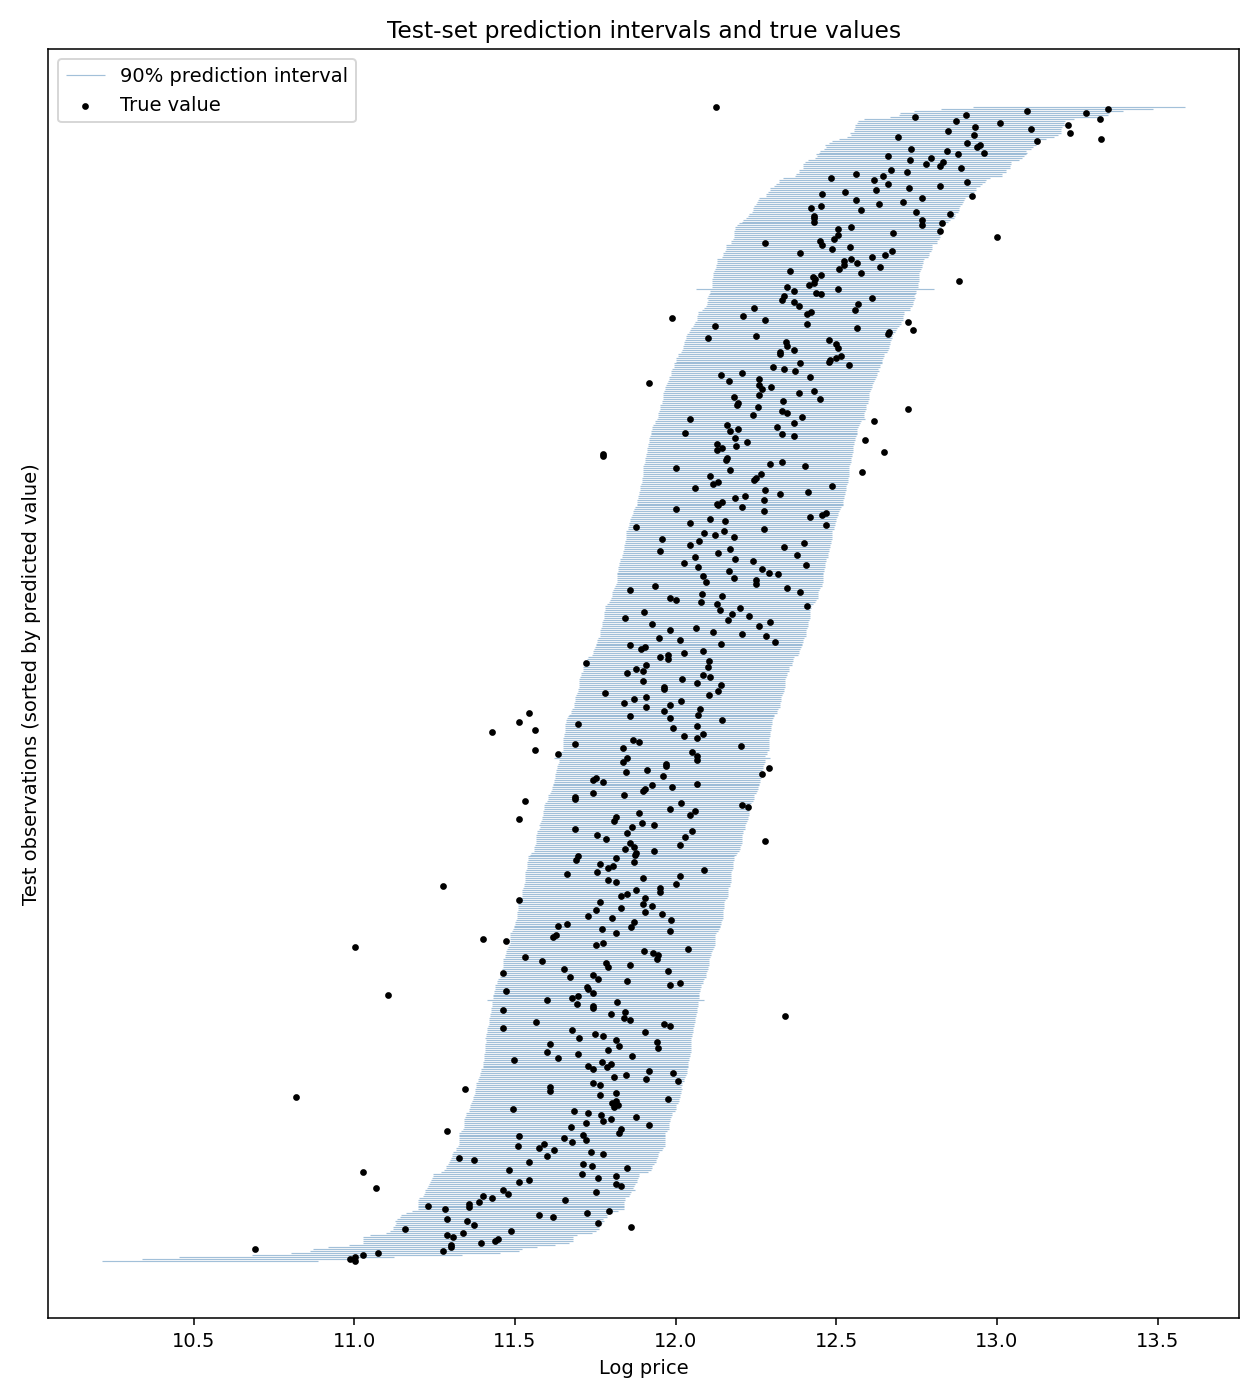

In [ ]:
plot_data = comparison.sort_values('predicted')
rows = np.arange(len(plot_data))

fig, ax = plt.subplots(figsize=(9, 10))
ax.hlines(rows, plot_data['lower'], plot_data['upper'],
          color='steelblue', alpha=0.5, linewidth=0.6, label='90% prediction interval')
ax.scatter(plot_data['actual'], rows, color='black', s=6, label='True value', zorder=3)
ax.set(xlabel='Log price', ylabel='Test observations (sorted by predicted value)',
       title='Test-set prediction intervals and true values', yticks=[])
ax.legend()
fig.tight_layout()
plt.show()

## Example: Other Losses
- What if, instead of a Gaussian error, we assumed it was distributed according to the Laplace distribution?
$$
f[y|\mu, \gamma] = \dfrac{1}{2\gamma} \exp \left\lbrace - \frac{|y-\mu|}{\gamma} \right\rbrace
$$
- The same work as above gives us a log-likelihood of
$$
L[y|\mu,\gamma] = -n\log(2) - n \log(\gamma)- \frac{1}{\gamma}\underbrace{\sum_{i=1}^n |y_i-\mu|}_{\text{Sum of Absolute Deviations}}
$$
- What $\hat{\mu}$ minimizes this? The median; this leads to median regression and quantile regression, when you model the conditional expectation as the median
- **Each loss function is connected probabilistically to a density function: You cannot separate these things conceptually**
- How would you do inference with this log-likelihood?